# Computer lab 2: convex and nonlinear optimization

**Mathematical Optimization, VU Amsterdam, 2026–27.**

For the continuous optimization problems, identify the domain and justify your
convexity claim before interpreting a numerical solution. Plots and repeated convergence from different
starting points can guide exploration, but neither proves convexity or global
optimality.
Exercise 5 parts 5–6 concern statistical evaluation; Exercise 7 concerns integer
linear modeling and formulation tests.

**Solutions.** Numerical results below are produced by the code.

## Setup

Run the next two cells for Exercises 1–6. They prepare Ipopt and the plotting
helpers. Exercise 7 has a separate HiGHS setup and can be run without Ipopt.
The first Colab setup can take a minute or more. It may print `Downloading Ipopt...`
before the `Week 2 ready` message; wait for that message before continuing.
Locally, missing Ipopt leaves the plotting and data cells available, but nonlinear
solve cells require its separate executable.
If asked to restart the session, restart and run Setup again. See the
[course setup instructions](https://github.com/alessandrozocca/MO2026#computer-lab-setup)
for local use and troubleshooting.

In [1]:
#@title Prepare course helpers and solvers
import hashlib
import os
from pathlib import Path
import sys
import time
import types
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

SETUP_COMMIT = '425c3f0af23e082c276df85fcde556538cc2abef'
SETUP_SHA256 = "f742478c6eaf5c5db82f4ce69b47a2adcf6f920765d88c3e7eb1b1ab72e66d28"
local_repo = os.environ.get("MO2026_REPO")
if local_repo:
    setup_location = str(Path(local_repo).expanduser() / "lab_setup.py")
    setup_source = Path(setup_location).read_bytes()
else:
    setup_location = f"https://raw.githubusercontent.com/alessandrozocca/MO2026/{SETUP_COMMIT}/lab_setup.py"
    for attempt in range(3):
        try:
            with urlopen(setup_location, timeout=30) as response:
                setup_source = response.read()
            break
        except (URLError, TimeoutError, ConnectionError) as error:
            if (isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504)) or attempt == 2:
                raise
            time.sleep(0.5 * (attempt + 1))
    if hashlib.sha256(setup_source).hexdigest() != SETUP_SHA256:
        raise RuntimeError("Course setup checksum mismatch; the downloaded code was not executed.")

lab_setup = types.ModuleType("mo2026_lab_setup")
lab_setup.__file__ = setup_location
sys.modules[lab_setup.__name__] = lab_setup
exec(compile(setup_source, setup_location, "exec"), lab_setup.__dict__)
if local_repo and lab_setup.API_VERSION != 1:
    raise RuntimeError("This notebook requires course setup API 1.")
lab = lab_setup.setup(week=2, optional_ipopt=True, check=False, verbose=True)
nlp_solver = lab.nlp_solver
def solve_and_load(model, solver=nlp_solver):
    if solver is None:
        raise RuntimeError("Ipopt is unavailable. Install its separate executable, then rerun Setup; see https://github.com/alessandrozocca/MO2026#running-locally-optional.")
    return lab_setup.solve_and_load(model, solver)
format_number = lambda value, digits=4: lab_setup.format_number(value, digits)
plotting = lab.helpers['tutorial2']
plot_feasible_region = plotting.plot_feasible_region
plot_objective = plotting.plot_objective

Week 2 ready: Pyomo 6.10.1; Ipopt 3.14.20 (Darwin arm64), ASL(20241202).


In [2]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo
import sympy as sp
from IPython.display import display

x1_sym, x2_sym = sp.symbols("x_1 x_2", real=True)

Useful references are [Chapter 5: Convex Optimization](https://mobook.github.io/MO-book/notebooks/05/05.00.html),
[Chapter 6: Conic Optimization](https://mobook.github.io/MO-book/notebooks/06/06.00.html)
and the [Ipopt documentation](https://coin-or.github.io/Ipopt/).
The finite windows in the plots are viewing windows, not additional constraints.

## Exercise 1: checking convexity

Consider

$$
\begin{aligned}
\min\quad &x_1^2+x_2\\
\text{s.t.}\quad &-x_1+x_2^2\le1,\\
&x_1+x_2\ge4,\qquad x_1,x_2\in\mathbb{R}.
\end{aligned}
$$

Is this a convex optimization problem? Justify your answer using the objective
and the constraint functions. Implement and solve it, then report the decisions
and objective value.

Ipopt checks local optimality conditions. Its `optimal` label does **not** certify
global optimality for a nonconvex problem; Exercise 3 has different local minima.
Global conclusions below use convexity and independent mathematical checks.
As in week 1, `solve_and_load` checks termination before loading the solution.
Here `solve_and_load` defaults to the prepared Ipopt solver; the worked calls
also pass it explicitly. Evaluate the returned solution with `pyo.value(...)`.

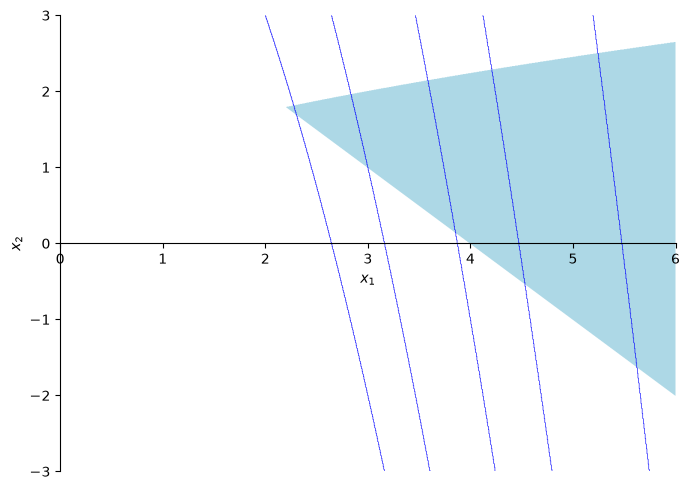

In [3]:
plot_1 = plot_feasible_region(
    [-x1_sym + x2_sym**2 <= 1, x1_sym + x2_sym >= 4],
    (x1_sym, 0, 6), (x2_sym, -3, 3), show=False, size=(7, 5),
)
plot_objective(plot_1, x1_sym**2 + x2_sym, [7, 10, 15, 20, 30])

### Solution

Write the inequalities as $g_1=-x_1+x_2^2-1\le0$ and
$g_2=4-x_1-x_2\le0$. The objective and first constraint function have Hessians

$$
\nabla^2 f=\begin{pmatrix}2&0\\0&0\end{pmatrix},\qquad
\nabla^2 g_1=\begin{pmatrix}0&0\\0&2\end{pmatrix}.
$$

Both are positive semidefinite, and $g_2$ is affine. The objective and feasible
set are therefore convex, and every local minimum is global.

Termination: optimal
x1 = 2.2087; x2 = 1.7913
Objective value: 6.6697


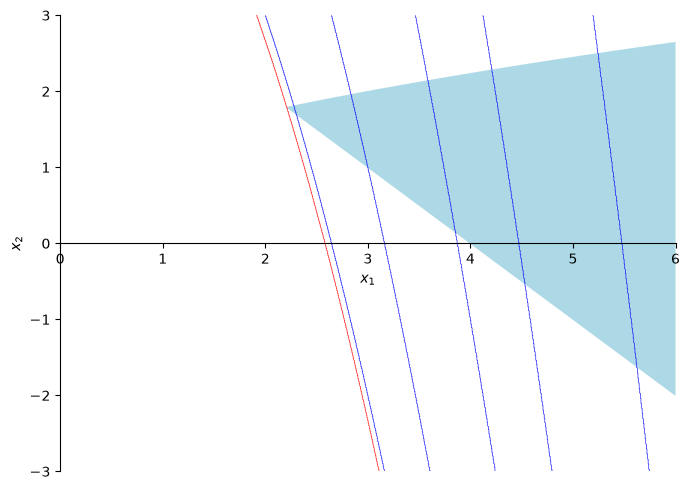

In [4]:
convex_model_1 = pyo.ConcreteModel(name="Exercise 1")
convex_model_1.x = pyo.Var([1, 2], domain=pyo.Reals, initialize={1: 3, 2: 1})
convex_model_1.objective = pyo.Objective(expr=convex_model_1.x[1]**2 + convex_model_1.x[2])
convex_model_1.curved = pyo.Constraint(expr=-convex_model_1.x[1] + convex_model_1.x[2]**2 <= 1)
convex_model_1.affine = pyo.Constraint(expr=convex_model_1.x[1] + convex_model_1.x[2] >= 4)

result = solve_and_load(convex_model_1, nlp_solver)
point_1 = np.array([pyo.value(convex_model_1.x[i]) for i in [1, 2]])
print(f"Termination: {result.solver.termination_condition}")
print(f"x1 = {format_number(point_1[0])}; x2 = {format_number(point_1[1])}")
print(f"Objective value: {format_number(pyo.value(convex_model_1.objective))}")
plot_objective(plot_1, x1_sym**2 + x2_sym, pyo.value(convex_model_1.objective), line_color="red")

The returned point makes both inequalities tight. Solving their two boundary
equations gives $x_1=(9-\sqrt{21})/2$, $x_2=(\sqrt{21}-1)/2$ for this intersection.
For $g_1=-x_1+x_2^2-1\le0$ and $g_2=4-x_1-x_2\le0$, stationarity is

$$
(2x_1,1)+\lambda_1(-1,2x_2)+\lambda_2(-1,-1)=0.
$$

At this point, $\lambda_1=(2x_1-1)/(2x_2+1)\approx0.746$ and
$\lambda_2=2x_1-\lambda_1\approx3.672$ are nonnegative. Both constraints
are tight, so complementary slackness also holds. These KKT conditions certify
global optimality for this convex problem. The red curve is the objective level
attained there.

## Exercise 2: exponential and quartic functions

Consider

$$
\begin{aligned}
\min\quad &x_1+e^{x_1+x_2}\\
\text{s.t.}\quad &x_1^4+x_2^4\le1,\\
&x_1-e^{x_2}\ge0,\qquad x_1,x_2\in\mathbb{R}.
\end{aligned}
$$

Justify whether this is a convex optimization problem. Put the inequalities in
the appropriate orientation for that argument, implement the model and solve it.
Use `pyo.exp` in Pyomo expressions and `sp.exp` for symbolic plots.

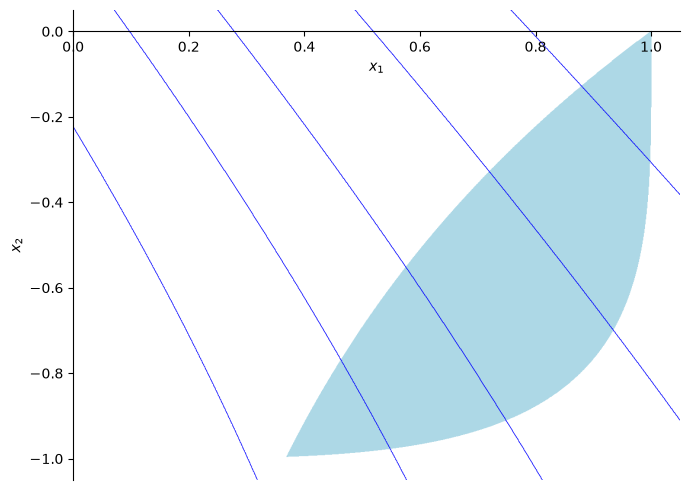

In [5]:
plot_2 = plot_feasible_region(
    [x1_sym**4 + x2_sym**4 <= 1, sp.exp(x2_sym) - x1_sym <= 0],
    (x1_sym, 0, 1.05), (x2_sym, -1.05, 0.05), show=False, size=(7, 5),
)
plot_objective(plot_2, x1_sym + sp.exp(x1_sym + x2_sym), [0.8, 1.2, 1.6, 2.2, 3])

### Solution

The objective is the sum of the linear term $x_1$ and $e^{x_1+x_2}$, the
exponential of an affine function. Both are convex, so the objective is convex.
The functions $x_1^4+x_2^4-1$ and $e^{x_2}-x_1$ are convex, and both are constrained
to be at most zero. Therefore the problem is convex.

Feasibility also implies $0<x_1\le1$ and $-1\le x_2\le0$: a positive $x_2$
would require $x_1>1$. We can give Ipopt these implied bounds without changing
the feasible set. They keep the exponential evaluations in a modest range.

Termination: optimal
x1 = 0.3696; x2 = -0.9953
Objective value: 0.9045


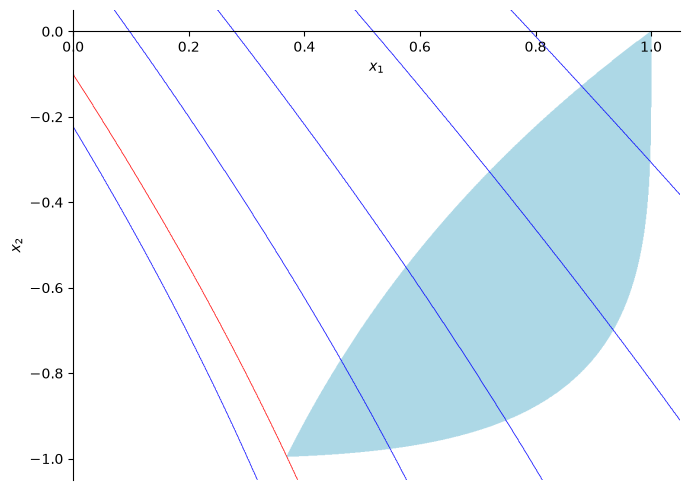

In [6]:
convex_model_2 = pyo.ConcreteModel(name="Exercise 2")
convex_model_2.x1 = pyo.Var(bounds=(0, 1), initialize=0.5)
convex_model_2.x2 = pyo.Var(bounds=(-1, 0), initialize=-0.8)
convex_model_2.objective = pyo.Objective(
    expr=convex_model_2.x1 + pyo.exp(convex_model_2.x1 + convex_model_2.x2)
)
convex_model_2.quartic = pyo.Constraint(expr=convex_model_2.x1**4 + convex_model_2.x2**4 <= 1)
convex_model_2.exponential = pyo.Constraint(expr=pyo.exp(convex_model_2.x2) - convex_model_2.x1 <= 0)

result = solve_and_load(convex_model_2, nlp_solver)
point_2 = np.array([pyo.value(convex_model_2.x1), pyo.value(convex_model_2.x2)])
print(f"Termination: {result.solver.termination_condition}")
print(f"x1 = {format_number(point_2[0])}; x2 = {format_number(point_2[1])}")
print(f"Objective value: {format_number(pyo.value(convex_model_2.objective))}")
plot_objective(plot_2, x1_sym + sp.exp(x1_sym + x2_sym),
               pyo.value(convex_model_2.objective), line_color="red")

For fixed $x_2$, the objective increases with $x_1$, so the optimal choice is
$x_1=e^{x_2}$. Substituting this leaves the feasibility condition
$e^{4x_2}+x_2^4\le1$. The resulting objective increases with $x_2$, so choose
the smallest feasible $x_2$, the negative root of $e^{4x_2}+x_2^4=1$.
This one-dimensional calculation independently checks the result.

## Exercise 3: local minima and a convex restriction

Consider

$$
\min_{-3.5\le x\le3.5} f(x),\qquad f(x)=x^4-11x^2-\frac{x}{10}.
$$

1. Compute $f''(x)$ and decide whether the problem is convex.
2. Solve it with Ipopt starting at $x=-2$ and $x=2$. Compare the returned points
   and function values. What can the solver's termination label establish here?
3. Does adding $x\ge0$ make the problem convex? Use $f''$ to decide, even if
   different starts converge to the same point.
4. Find a lower bound $a>0$ such that the restriction $a\le x\le3.5$ is convex.
   Solve that restriction from several valid starting points. Explain why it
   retains the original global minimizer for this particular function.

Restricting a domain generally changes the optimization problem; retaining a
global minimizer needs a separate argument.

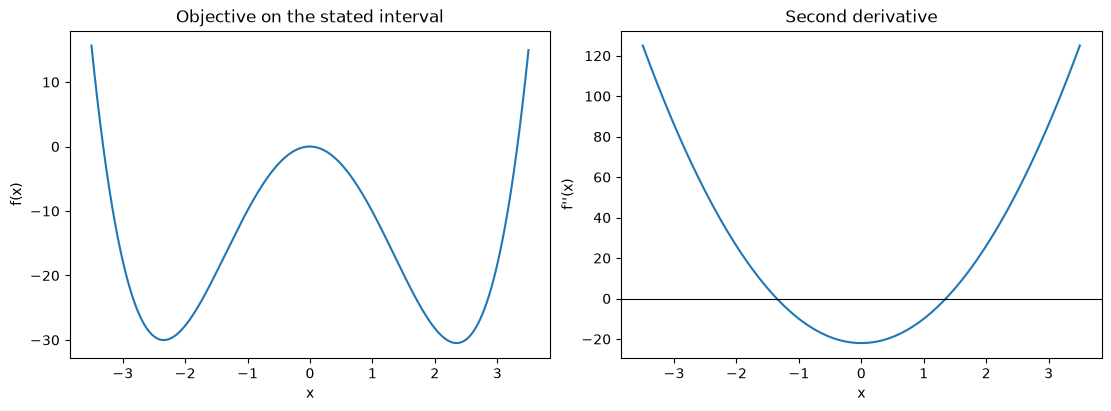

In [7]:
def quartic(value):
    return value**4 - 11 * value**2 - value / 10

quartic_grid = np.linspace(-3.5, 3.5, 600)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(quartic_grid, quartic(quartic_grid))
axes[0].set(xlabel="x", ylabel="f(x)", title="Objective on the stated interval")
axes[1].plot(quartic_grid, 12 * quartic_grid**2 - 22)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="x", ylabel="f''(x)", title="Second derivative")
plt.show()

### Solution

Here $f''(x)=12x^2-22$, which is negative when
$|x|<\sqrt{11/6}$. The original problem is nonconvex, and so is the restriction
$0\le x\le3.5$. On the latter interval, $f'$ first decreases and then increases
through zero once: there is a single minimum, despite the lack of convexity.

The restriction $\sqrt{11/6}\le x\le3.5$ is convex. For $x>0$,
$f(x)<f(-x)$, so no negative point can be a global minimizer. Also $f'<0$ on
$[0,\sqrt{11/6}]$, so discarding that interval does not remove a global minimizer.
Together these facts justify the restriction for this function.

,Domain,Start,Returned x,f(x),Termination
0,Full interval,-2.0000,-2.3429,-30.0156,optimal
1,Full interval,2.0000,2.3475,-30.4846,optimal
2,Nonnegative interval,0.2000,2.3475,-30.4846,optimal
3,Nonnegative interval,2.0000,2.3475,-30.4846,optimal
4,Nonnegative interval,3.4000,2.3475,-30.4846,optimal
5,Convex interval,1.4040,2.3475,-30.4846,optimal
6,Convex interval,2.0000,2.3475,-30.4846,optimal
7,Convex interval,3.4000,2.3475,-30.4846,optimal


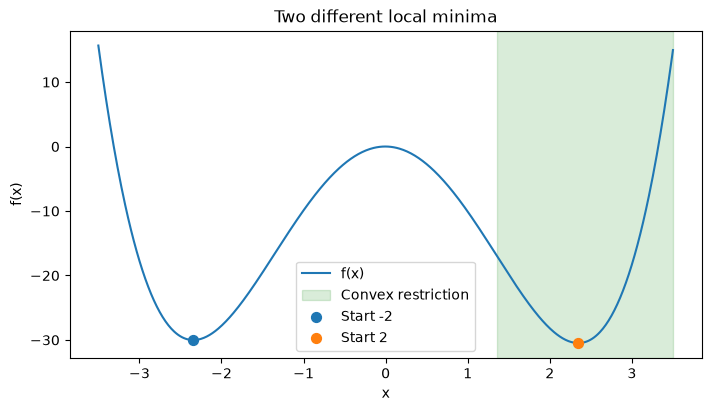

In [8]:
def build_quartic(start, lower=-3.5, upper=3.5):
    if not lower <= start <= upper:
        raise ValueError("Choose a starting point inside the stated bounds.")
    model = pyo.ConcreteModel(name="Quartic example")
    model.x = pyo.Var(bounds=(lower, upper), initialize=start)
    model.objective = pyo.Objective(expr=model.x**4 - 11 * model.x**2 - model.x / 10)
    return model

convex_lower = np.sqrt(11 / 6)
quartic_cases = [
    ("Full interval", -3.5, [-2, 2]),
    ("Nonnegative interval", 0, [0.2, 2, 3.4]),
    ("Convex interval", convex_lower, [convex_lower + 0.05, 2, 3.4]),
]
quartic_models = []
quartic_rows = []
for name, lower, starts in quartic_cases:
    for start in starts:
        model = build_quartic(start, lower=lower)
        result = solve_and_load(model, nlp_solver)
        value = pyo.value(model.x)
        quartic_models.append((name, start, model))
        quartic_rows.append({
            "Domain": name, "Start": start, "Returned x": value,
            "f(x)": quartic(value), "Termination": str(result.solver.termination_condition),
        })

quartic_results = pd.DataFrame(quartic_rows)
display(quartic_results.style.format(
    {"Start": format_number, "Returned x": format_number, "f(x)": format_number}
))

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(quartic_grid, quartic(quartic_grid), label="f(x)")
ax.axvspan(convex_lower, 3.5, alpha=0.15, color="green", label="Convex restriction")
for name, start, model in quartic_models[:2]:
    value = pyo.value(model.x)
    ax.scatter(value, quartic(value), s=50, label=f"Start {start:g}", zorder=3)
ax.set(xlabel="x", ylabel="f(x)", title="Two different local minima")
ax.legend()
plt.show()

Both full-interval runs report `optimal`: Ipopt has satisfied its local
optimality tolerances. This is not a global certificate. The start $x=-2$
returns a local minimum with $f(x)\approx-30.016$, which is worse than the
value $f(x)\approx-30.485$ returned from $x=2$.

For an independent global check, solve $f'(x)=4x^3-22x-0.1=0$ and evaluate $f$
at every real stationary point in the interval and at both endpoints. The smallest
of these finitely many values is the global optimum. Repeated Ipopt convergence
alone would not establish this comparison.

In [9]:
derivative_roots = np.roots([4, 0, -22, -0.1])
stationary_points = np.sort(derivative_roots[np.abs(derivative_roots.imag) < 1e-10].real)
stationary_points = stationary_points[(stationary_points >= -3.5) & (stationary_points <= 3.5)]
quartic_candidates = np.r_[-3.5, stationary_points, 3.5]
candidate_table = pd.DataFrame({"Candidate x": quartic_candidates, "f(x)": quartic(quartic_candidates)})
display(candidate_table.style.format(format_number))
best_index = np.argmin(quartic(quartic_candidates))
quartic_global_x = quartic_candidates[best_index]
print(f"Global minimizer: {format_number(quartic_global_x)}")
print(f"Global minimum: {format_number(quartic(quartic_global_x))}")

,Candidate x,f(x)
0,-3.5000,15.6625
1,-2.3429,-30.0156
2,-0.0045,0.0002
3,2.3475,-30.4846
4,3.5000,14.9625


Global minimizer: 2.3475
Global minimum: -30.4846


## Exercise 4: domains and an epigraph

Consider

$$
\begin{aligned}
\min\quad &\max\left\{\frac1{x_1-x_2},\frac{(x_1+4x_2)^2}{x_2}\right\}\\
\text{s.t.}\quad &x_1+x_2\ge\frac23,\qquad x_1,x_2\ge0.
\end{aligned}
$$

The objective is defined only when $x_2>0$ and $x_1\ne x_2$.

1. Explain why the natural feasible domain is not convex. Show that restricting
   to $x_1>x_2>0$ gives a convex problem.
2. Introduce an epigraph variable for the maximum and implement the positive-domain
   problem. Keep every denominator positive during the numerical solve.
3. Report the solution and check both original objective terms. Does the restricted
   solution also minimize the objective over the full natural domain? Justify
   that conclusion mathematically.

### Solution

The points $(1,1/2)$ and $(1/2,1)$ satisfy the constraints and lie in the natural
domain, but their midpoint $(3/4,3/4)$ is excluded because $x_1=x_2$. Thus the
natural feasible domain is not convex.

On the positive branch $x_1>x_2>0$, $1/(x_1-x_2)$ is a convex reciprocal of a
positive affine function, and $(x_1+4x_2)^2/x_2$ is convex quadratic-over-linear.
Their maximum is convex.

Minimize $T$ subject to each term being at most $T$. To protect denominator
evaluations, use variables $u=x_1-x_2$ and $v=x_2$, so $x_1=u+v$:

$$
\begin{aligned}
\min\quad &T\\
\text{s.t.}\quad &1/u\le T,\\
&(u+5v)^2/v\le T,\\
&u+2v\ge2/3,\qquad u>0,\ v>0.
\end{aligned}
$$

The code imposes $u,v\ge\varepsilon=10^{-6}$ and starts inside this domain.
This numerically restricts the open positive domain. The analytic optimizer below
has $u=v=2/9$, so the bounds retain its optimum. A positive epsilon must be checked
again if the data change.

In [10]:
def build_minimax(epsilon=1e-6):
    if epsilon <= 0:
        raise ValueError("epsilon must be positive.")
    model = pyo.ConcreteModel(name="Positive-domain minimax")
    model.gap = pyo.Var(bounds=(epsilon, None), initialize=max(0.25, 2 * epsilon))
    model.x2 = pyo.Var(bounds=(epsilon, None), initialize=max(0.25, 2 * epsilon))
    model.x1 = pyo.Expression(expr=model.gap + model.x2)
    model.epigraph = pyo.Var(domain=pyo.NonNegativeReals, initialize=10)
    model.objective = pyo.Objective(expr=model.epigraph)
    model.reciprocal = pyo.Constraint(expr=1 / model.gap <= model.epigraph)
    model.quadratic_over_linear = pyo.Constraint(
        expr=(model.gap + 5 * model.x2)**2 / model.x2 <= model.epigraph
    )
    model.sum_limit = pyo.Constraint(expr=model.gap + 2 * model.x2 >= 2 / 3)
    return model

domain_epsilon = 1e-6
minimax_model = build_minimax(domain_epsilon)
result = solve_and_load(minimax_model, nlp_solver)
point_4 = np.array([pyo.value(minimax_model.x1), pyo.value(minimax_model.x2)])
objective_terms = np.array([1 / (point_4[0] - point_4[1]),
                            (point_4[0] + 4 * point_4[1])**2 / point_4[1]])
print(f"Termination: {result.solver.termination_condition}")
print(f"x1 = {format_number(point_4[0])}; x2 = {format_number(point_4[1])}")
print(f"Original objective terms: {format_number(objective_terms[0])}, {format_number(objective_terms[1])}")
print(f"Maximum of the terms: {format_number(objective_terms.max())}")
print(f"Epigraph value: {format_number(pyo.value(minimax_model.epigraph))}")

Termination: optimal
x1 = 0.4444; x2 = 0.2222
Original objective terms: 4.5000, 8.0000
Maximum of the terms: 8.0000
Epigraph value: 8.0000


Let $s=x_1+x_2$. At every point of the full natural domain, $s\ge2/3$ and $x_2>0$.
The arithmetic–geometric mean inequality gives

$$
\frac{(x_1+4x_2)^2}{x_2}
=\frac{s^2}{x_2}+6s+9x_2
\ge12s\ge8.
$$

Thus the maximum of the two terms is at least 8 on **both** branches.
At $(x_1,x_2)=(4/9,2/9)$, the terms are $9/2$ and $8$, so the lower bound is
attained. This proves global optimality for the original natural domain and
justifies retaining only the positive branch for this instance.

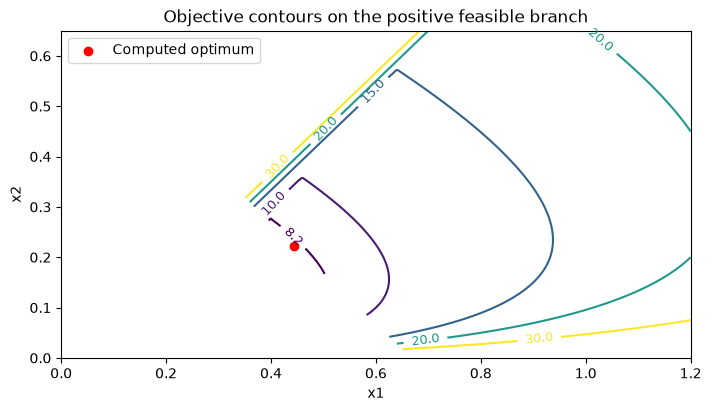

In [11]:
# Evaluate only points in the positive feasible domain; avoid the singularities.
grid_x1, grid_x2 = np.meshgrid(np.linspace(0, 1.2, 350), np.linspace(0, 0.65, 250))
valid = (grid_x1 > grid_x2) & (grid_x2 > 0) & (grid_x1 + grid_x2 >= 2 / 3)
grid_objective = np.full_like(grid_x1, np.nan)
grid_objective[valid] = np.maximum(
    1 / (grid_x1[valid] - grid_x2[valid]),
    (grid_x1[valid] + 4 * grid_x2[valid])**2 / grid_x2[valid],
)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
contours = ax.contour(grid_x1, grid_x2, grid_objective, levels=[8.2, 10, 15, 20, 30])
for label in ax.clabel(contours, inline=True, fontsize=9):
    label.set_clip_on(False)
ax.scatter(*point_4, color="red", label="Computed optimum", zorder=3)
ax.set(xlabel="x1", ylabel="x2", title="Objective contours on the positive feasible branch")
ax.legend()
plt.show()

## Exercise 5: ordinary least squares and a conic formulation

For observations $i=0,\ldots,n-1$ with features $X_{ij}$, $j=0,\ldots,k-1$, fit
an intercept $b$ and slopes $m_j$ by ordinary least squares (OLS):

$$
\begin{aligned}
\min\quad &\sum_{i=0}^{n-1}e_i^2\\
\text{s.t.}\quad &e_i=y_i-b-\sum_{j=0}^{k-1}X_{ij}m_j\quad\text{for each }i,\\
&b,m_j,e_i\in\mathbb{R}.
\end{aligned}
$$

1. Implement a function `build_ols(X, y)` returning an unsolved model. Fit the
   supplied data with Ipopt and report the intercept, slopes and sum of squared
   residuals (SSE).
2. Prove that the problem is convex. When are the fitted coefficients unique?
3. Introduce $t$ and write a second-order cone formulation minimizing the
   **Euclidean residual norm**. Explain why it gives the same fitted coefficients
   as OLS, and report its optimal value using your fit. Distinguish that value
   from the SSE.
4. Compare your coefficients and residuals with `np.linalg.lstsq`, including a
   column of ones for the intercept.
5. Freeze this fit and evaluate mean squared error (MSE) on the supplied
   independent test sample. The supplied test sample uses the same true slopes,
   a zero true intercept, standard normal features and independent noise with
   standard deviation 75.
   Why is MSE preferable to SSE when sample sizes differ? Must the test MSE
   exceed the training MSE in this one comparison?
6. Repeat 200 fits with only 30 training observations, using `np.linalg.lstsq`
   with an intercept and the same fixed true slopes/test sample. Compare mean
   training and test MSE. Explain the distinction between an average effect and
   what can happen in one realization. Never refit using the test responses.

Use the smooth squared objective for the numerical Ipopt solve. The conic part
asks for the formulation and its relation to that solution.

In [12]:
from sklearn.datasets import make_regression

X, y, true_slopes = make_regression(
    n_samples=500, n_features=5, noise=75, random_state=2022, coef=True
)
print(f"Data: {X.shape[0]} observations, {X.shape[1]} features; response shape {y.shape}")

Data: 500 observations, 5 features; response shape (500,)


In [13]:
evaluation_rng = np.random.default_rng(2026)
X_test = evaluation_rng.normal(size=(5000, X.shape[1]))
y_test = X_test @ true_slopes + evaluation_rng.normal(0, 75, len(X_test))

### Solution

The objective is a sum of convex squares and the residual equalities are affine,
so the model is convex. Equivalently, with $A=[\mathbf{1}\;X]$ and
$\theta=(b,m_0,\ldots,m_{k-1})$, it minimizes
$\|y-A\theta\|_2^2$, whose Hessian is $2A^\top A\succeq0$.
Coefficients are unique if and only if $A$ has full column rank. Without full
rank, the fitted response and residual vector are still unique, even if
coefficients are not.

In [14]:
def build_ols(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    if X.ndim != 2 or y.shape != (X.shape[0],):
        raise ValueError("X must be a matrix and y an aligned one-dimensional response.")
    n, k = X.shape
    model = pyo.ConcreteModel(name="Ordinary least squares")
    model.observations = pyo.RangeSet(0, n - 1)
    model.features = pyo.RangeSet(0, k - 1)
    model.intercept = pyo.Var(domain=pyo.Reals, initialize=0)
    model.slope = pyo.Var(model.features, domain=pyo.Reals, initialize=0)
    model.residual = pyo.Var(model.observations, domain=pyo.Reals,
                             initialize={i: y[i] for i in range(n)})

    @model.Constraint(model.observations)
    def residual_definition(m, i):
        return m.residual[i] == y[i] - m.intercept - sum(X[i, j] * m.slope[j] for j in m.features)

    model.objective = pyo.Objective(expr=sum(model.residual[i]**2 for i in model.observations))
    return model

ols_model = build_ols(X, y)
result = solve_and_load(ols_model, nlp_solver)
ols_coefficients = np.r_[pyo.value(ols_model.intercept),
                          [pyo.value(ols_model.slope[j]) for j in ols_model.features]]
A = np.column_stack([np.ones(len(y)), X])
ols_residuals = y - A @ ols_coefficients
ols_sse = ols_residuals @ ols_residuals
print(f"Termination: {result.solver.termination_condition}")
display(pd.Series(ols_coefficients, index=["Intercept"] + [f"m_{j}" for j in ols_model.features],
                  name="Coefficient").to_frame().style.format(format_number))
print(f"Sum of squared residuals: {ols_sse:.6f}")

Termination: optimal


,Coefficient
Intercept,-5.9690
m_0,71.1443
m_1,87.8850
m_2,31.8960
m_3,84.7203
m_4,13.3295


Sum of squared residuals: 3011210.753257


The second-order cone formulation is

$$
\begin{aligned}
\min\quad &t\\
\text{s.t.}\quad &\|e\|_2\le t,\\
&e_i=y_i-b-\sum_j X_{ij}m_j\quad\text{for each }i.
\end{aligned}
$$

Its first constraint is $(t,e)\in\mathcal{Q}_{n+1}$ and implies $t\ge0$.
Because squaring is strictly increasing on $[0,\infty)$, minimizing the residual
norm or its square gives the same coefficient minimizers. The objective values
are $\sqrt{\mathrm{SSE}}$ and $\mathrm{SSE}$, respectively.

Ipopt solves the smooth quadratic formulation here. The conic optimum is then
recovered from the equivalence above; no separate conic solver is used.

,Ipopt OLS,NumPy lstsq
Intercept,-5.9690,-5.9690
m_0,71.1443,71.1443
m_1,87.8850,87.8850
m_2,31.8960,31.8960
m_3,84.7203,84.7203
m_4,13.3295,13.3295


Design rank: 6 out of 6 columns
Maximum coefficient difference: 1.42e-13
Quadratic objective (SSE): 3011210.753257
Conic objective (residual norm): 1735.284055


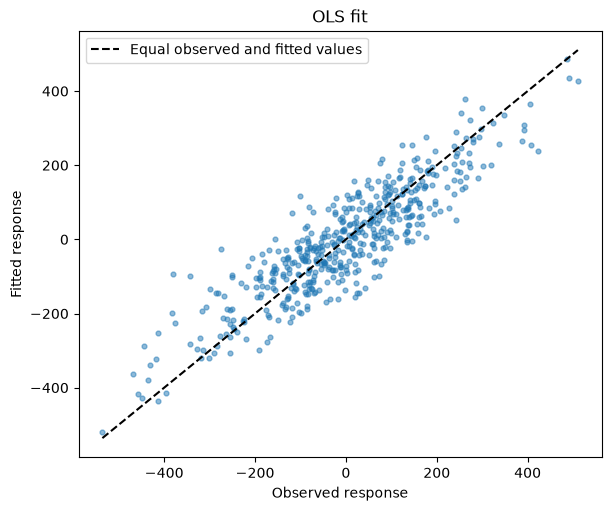

In [15]:
numpy_coefficients, _, design_rank, _ = np.linalg.lstsq(A, y, rcond=None)
numpy_residuals = y - A @ numpy_coefficients
coefficient_comparison = pd.DataFrame(
    {"Ipopt OLS": ols_coefficients, "NumPy lstsq": numpy_coefficients},
    index=["Intercept"] + [f"m_{j}" for j in range(X.shape[1])],
)
display(coefficient_comparison.style.format(format_number))
conic_value = np.linalg.norm(ols_residuals)
print(f"Design rank: {design_rank} out of {A.shape[1]} columns")
print(f"Maximum coefficient difference: {np.max(np.abs(ols_coefficients - numpy_coefficients)):.2e}")
print(f"Quadratic objective (SSE): {ols_sse:.6f}")
print(f"Conic objective (residual norm): {conic_value:.6f}")

fitted = A @ ols_coefficients
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.scatter(y, fitted, s=12, alpha=0.5)
limits = [min(y.min(), fitted.min()), max(y.max(), fitted.max())]
ax.plot(limits, limits, color="black", linestyle="--", label="Equal observed and fitted values")
ax.set(xlabel="Observed response", ylabel="Fitted response", title="OLS fit")
ax.legend()
plt.show()

### Fitting versus evaluation

Keep the fitted intercept and slopes fixed when predicting the independent test
responses. For the smaller-sample experiment, draw training samples **after**
the test sample, using the supplied `evaluation_rng`. Each training sample has
30 independent standard normal feature vectors and independent $N(0,75^2)$ noise.
Within each replication, draw the full feature matrix first, then the noise
vector. The true slopes are fixed throughout.

,MSE
Training (n=500),6022.42
Independent test,5696.65


,Mean over 200 fits
Training MSE,4422.60
Test MSE,7049.88


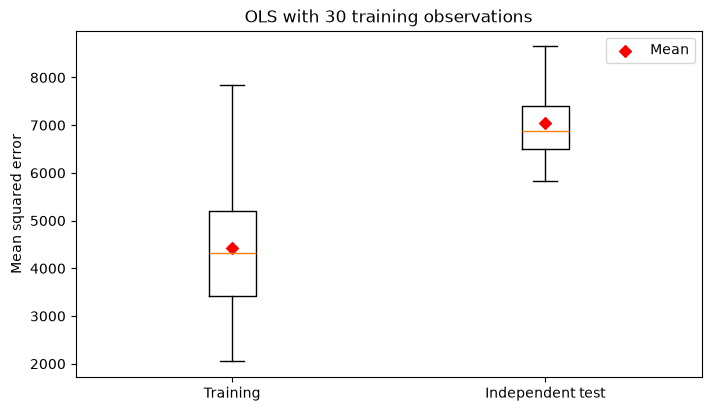

In [16]:
test_design = np.column_stack([np.ones(len(y_test)), X_test])
training_mse = np.mean(ols_residuals**2)
test_mse = np.mean((y_test - test_design @ ols_coefficients)**2)
display(pd.Series({"Training (n=500)": training_mse, "Independent test": test_mse},
                  name="MSE").to_frame().style.format("{:.2f}"))

replication_rows = []
for replication in range(200):
    X_small = evaluation_rng.normal(size=(30, X.shape[1]))
    y_small = X_small @ true_slopes + evaluation_rng.normal(0, 75, len(X_small))
    small_design = np.column_stack([np.ones(len(y_small)), X_small])
    coefficients, *_ = np.linalg.lstsq(small_design, y_small, rcond=None)
    replication_rows.append({
        "Training MSE": np.mean((y_small - small_design @ coefficients)**2),
        "Test MSE": np.mean((y_test - test_design @ coefficients)**2),
    })
replication_mse = pd.DataFrame(replication_rows)
display(replication_mse.mean().rename("Mean over 200 fits").to_frame().style.format("{:.2f}"))
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.boxplot([replication_mse["Training MSE"], replication_mse["Test MSE"]], showfliers=False)
ax.set_xticks([1, 2], ["Training", "Independent test"])
ax.scatter([1, 2], replication_mse.mean(), marker="D", color="red", label="Mean")
ax.set(ylabel="Mean squared error", title="OLS with 30 training observations")
ax.legend()
plt.show()

SSE grows with sample size, whereas MSE averages the squared error per observation.
The original fit has training MSE about 6022 and test MSE about 5697: this one
sample reverses the expected ordering. Optimizing on the training observations
makes their error optimistic **in expectation**, not in every realization.
The 200 smaller fits have mean training/test MSE about 4423/7050; their boxplots
also show substantial variability.

For independent Gaussian feature rows $N(0,I_k)$, independent homoscedastic noise
of variance $\sigma^2$, a correctly specified linear response with fixed slopes,
and a fitted intercept, the expected MSEs for $n>k+2$ are

$$
\mathbb{E}[\mathrm{MSE}_{\rm train}]
 =\sigma^2\left(1-\frac{k+1}{n}\right),\qquad
\mathbb{E}[\mathrm{MSE}_{\rm test}]
 =\sigma^2\left(1+\frac1n\right)\left(1+\frac{k}{n-k-2}\right).
$$

The first identity follows from the residual projection's rank $n-k-1$; the
second averages prediction risk over the Gaussian training design and an
independent test observation, including estimation of the intercept. With
$k=5$, $\sigma=75$, these are 5557.5/5693.4 for $n=500$ and 4500/7076.1 for $n=30$.
A finite test sample estimates that risk. Reusing one independent test sample
across replications does not make the replications' test errors independent.
This experiment keeps the data-generating law fixed; it does not assess changes
in that law between training and deployment.

## Exercise 6: Markowitz portfolio optimization

An investor allocates capital $C$ among $n$ risky assets and a risk-free asset.
Let $x_i$ be the amount invested in risky asset $i$, and $\tilde x$ the risk-free
amount. Short selling and borrowing are excluded.

The risky **gross return factors** form a random vector $r$ with mean $\mu$ and
covariance $\Sigma$. A gross factor of 1.2 means that one invested unit becomes
1.2 units. The risk-free gross factor is $R$. Terminal wealth is
$W=R\tilde x+r^\top x$, so

$$
\mathbb{E}W=R\tilde x+\mu^\top x,\qquad
\operatorname{Var}(W)=x^\top\Sigma x.
$$

Maximize expected wealth subject to a variance limit $\gamma$:

$$
\begin{aligned}
\max\quad &R\tilde x+\sum_i\mu_i x_i\\
\text{s.t.}\quad &\sum_i x_i+\tilde x=C,\\
&x^\top\Sigma x\le\gamma,\\
&x_i\ge0,\quad\tilde x\ge0.
\end{aligned}
$$

1. Explain why the problem is convex when $\Sigma\succeq0$.
2. Implement a function `build_portfolio(data)` returning an unsolved model and
   solve the supplied instance. Infer the number of assets from the data.
3. Report the allocation, expected terminal wealth, expected gain above initial
   capital, and the variance and standard deviation of wealth. Check the budget
   and explain whether the risk limit is active.

These are **illustrative data**, with large return variances. Capital and wealth
are in currency units; $\gamma$ is in squared currency units. The standard
deviation is the square root of the variance, not the variance itself.

In [17]:
@dataclass
class PortfolioData:
    capital: float
    variance_limit: float
    risk_free: float
    mean: np.ndarray
    covariance: np.ndarray

portfolio_data = PortfolioData(
    capital=1,
    variance_limit=1,
    risk_free=1.01,
    mean=np.array([1.2, 1.1, 1.3]),
    covariance=np.array([[1.5, 0.5, 2], [0.5, 2, 0], [2, 0, 5]]),
)
display(pd.DataFrame(
    {"Mean gross factor": portfolio_data.mean,
     "Gross-factor standard deviation": np.sqrt(np.diag(portfolio_data.covariance))},
    index=[f"Asset {i + 1}" for i in range(len(portfolio_data.mean))],
).style.format(format_number))

,Mean gross factor,Gross-factor standard deviation
Asset 1,1.2000,1.2247
Asset 2,1.1000,1.4142
Asset 3,1.3000,2.2361


### Solution

The expected-wealth objective and budget equality are affine, and nonnegativity
defines a convex set. Since $\Sigma$ is positive semidefinite, the variance
function has Hessian $2\Sigma\succeq0$, and its
sublevel set is convex. Maximizing an affine function over this set is a convex
optimization problem.

The code writes the expected wealth and variance as explicit indexed sums.
The covariance matrix and risk limit are kept at their given scale.

In [18]:
def build_portfolio(data):
    mean = np.asarray(data.mean, dtype=float)
    covariance = np.asarray(data.covariance, dtype=float)
    n = len(mean)
    if mean.ndim != 1 or covariance.shape != (n, n):
        raise ValueError("Mean and covariance dimensions must agree.")
    if not np.allclose(covariance, covariance.T) or np.linalg.eigvalsh(covariance).min() < -1e-10:
        raise ValueError("The covariance matrix must be symmetric positive semidefinite.")
    if data.capital <= 0 or data.variance_limit < 0:
        raise ValueError("Use positive capital and a nonnegative variance limit.")
    model = pyo.ConcreteModel(name="Markowitz portfolio")
    model.assets = pyo.RangeSet(0, n - 1)
    model.cash = pyo.Var(domain=pyo.NonNegativeReals, initialize=data.capital)
    model.investment = pyo.Var(model.assets, domain=pyo.NonNegativeReals, initialize=0)
    model.objective = pyo.Objective(
        expr=data.risk_free * model.cash + sum(mean[i] * model.investment[i] for i in model.assets),
        sense=pyo.maximize,
    )
    model.budget = pyo.Constraint(
        expr=model.cash + sum(model.investment[i] for i in model.assets) == data.capital
    )
    model.variance = pyo.Expression(
        expr=sum(covariance[i, j] * model.investment[i] * model.investment[j]
                 for i in model.assets for j in model.assets)
    )
    model.risk_limit = pyo.Constraint(expr=model.variance <= data.variance_limit)
    return model

portfolio_model = build_portfolio(portfolio_data)
result = solve_and_load(portfolio_model, nlp_solver)
portfolio_risky = np.array([pyo.value(portfolio_model.investment[i]) for i in portfolio_model.assets])
portfolio_cash = pyo.value(portfolio_model.cash)
portfolio_wealth = portfolio_data.mean @ portfolio_risky + portfolio_data.risk_free * portfolio_cash
portfolio_variance = portfolio_risky @ portfolio_data.covariance @ portfolio_risky
allocation = pd.DataFrame(
    {"Amount": np.r_[portfolio_risky, portfolio_cash],
     "Share of capital (%)": 100 * np.r_[portfolio_risky, portfolio_cash] / portfolio_data.capital},
    index=[f"Asset {i + 1}" for i in portfolio_model.assets] + ["Risk-free"],
)
print(f"Termination: {result.solver.termination_condition}")
display(allocation.style.format(format_number))
print(f"Expected terminal wealth: {portfolio_wealth:.6f}")
print(f"Expected gain: {portfolio_wealth - portfolio_data.capital:.6f}")
print(f"Wealth variance: {portfolio_variance:.6f} (limit {portfolio_data.variance_limit:g})")
print(f"Wealth standard deviation: {np.sqrt(portfolio_variance):.6f}")
print(f"Total invested: {portfolio_risky.sum() + portfolio_cash:.6f}")

Termination: optimal


,Amount,Share of capital (%)
Asset 1,0.5611,56.1071
Asset 2,0.1416,14.1629
Asset 3,0.1389,13.8906
Risk-free,0.1584,15.8394


Expected terminal wealth: 1.169633
Expected gain: 0.169633
Wealth variance: 1.000000 (limit 1)
Wealth standard deviation: 1.000000
Total invested: 1.000000


The returned variance reaches the allowed limit. All three risky holdings and
the risk-free amount are positive for these data. Since every $\mu_i>R$, moving
a small amount from the positive cash holding to any risky asset would increase
expected wealth. If the variance constraint were slack, continuity would make
a sufficiently small such transfer feasible, contradicting optimality. Thus the
risk limit must be active.

The risk-free holding contributes expected wealth but no variance; it also lets
the investor satisfy the budget without putting every unit into risky assets.
The expected gain is expected terminal wealth minus initial capital.

## Exercise 7: a coordination surcharge and controlled tests

A shipping company pays fixed costs when ships visit ports, as in W1 Exercise 6.
It now pays a coordination surcharge $\kappa q$, $\kappa>0$, when Ship 4 visits
both Port 5 and Port 9. Write $a=x_{\text{Ship 4},\text{Port 5}}$,
$b=x_{\text{Ship 4},\text{Port 9}}$ and require $q=ab$.

1. Derive an exact linear formulation with continuous $q\in[0,1]$ and binary
   $a,b$. Implement `add_coordination(model, ship, port_a, port_b, kappa)`.
   Update `model.objective.expr`; do not create a second active objective.
2. Test your product formulation on a separate three-variable model. Fix each
   binary pair and minimize **and** maximize $q$: both endpoints must equal
   $ab$. Fixed visits in the shipping model can cause unrelated infeasibility,
   so they are unsuitable for this isolated truth-table test.
3. Solve the base model and the model with $a+b\le1$; call their values $V_0$
   and $V_{\rm avoid}$. Establish that every base optimum uses both visits.
   Derive $V(\kappa)=\min\{V_0+\kappa,V_{\rm avoid}\}$ for $\kappa\ge0$ and predict
   the decisions at $\kappa=50$ and $200$ before solving. Locate the switch.
4. The supplied incomplete extension omits one product inequality. Exhibit a
   test that fails for it and passes for your corrected extension. Explain why
   testing just one favorable objective can miss a modeling error.
5. With $q$ appearing only in this positive surcharge, which inequalities suffice
   at an optimum? Check this reduced formulation at both surcharge values, but
   do not claim that its feasible set equals the full product graph. Keep the
   inequalities that stop the objective from pushing $q$ away from $ab$;
   reconsider the simplification if the objective changes.
6. Separately, list the allowed binary values of $r$ under $r\ge a-b$ for all
   four binary pairs. State the implication it enforces and distinguish it
   from an equivalence.

You can start Exercise 7 in a fresh session: run the setup form and supplied
base-model cell below. It uses **HiGHS only** and does not require Ipopt or the
results of earlier exercises. Build a fresh shipping model for every test.

In [19]:
#@title Prepare HiGHS for Exercise 7
import hashlib
import os
from pathlib import Path
import sys
import time
import types
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

SETUP_COMMIT = '425c3f0af23e082c276df85fcde556538cc2abef'
SETUP_SHA256 = "f742478c6eaf5c5db82f4ce69b47a2adcf6f920765d88c3e7eb1b1ab72e66d28"
local_repo = os.environ.get("MO2026_REPO")
if local_repo:
    setup_location = str(Path(local_repo).expanduser() / "lab_setup.py")
    setup_source = Path(setup_location).read_bytes()
else:
    setup_location = f"https://raw.githubusercontent.com/alessandrozocca/MO2026/{SETUP_COMMIT}/lab_setup.py"
    for attempt in range(3):
        try:
            with urlopen(setup_location, timeout=30) as response:
                setup_source = response.read()
            break
        except (URLError, TimeoutError, ConnectionError) as error:
            if (isinstance(error, HTTPError) and error.code not in (408, 429, 500, 502, 503, 504)) or attempt == 2:
                raise
            time.sleep(0.5 * (attempt + 1))
    if hashlib.sha256(setup_source).hexdigest() != SETUP_SHA256:
        raise RuntimeError("Course setup checksum mismatch; the downloaded code was not executed.")

lab_setup = types.ModuleType("mo2026_lab_setup")
lab_setup.__file__ = setup_location
sys.modules[lab_setup.__name__] = lab_setup
exec(compile(setup_source, setup_location, "exec"), lab_setup.__dict__)
if local_repo and lab_setup.API_VERSION != 1:
    raise RuntimeError("This notebook requires course setup API 1.")
lab = lab_setup.setup(week=2, solvers=("appsi_highs",), check=False, verbose=True)
solve = lab_setup.solve

Week 2 ready: Pyomo 6.10.1; HiGHS 1.15.1.


In [20]:
import numpy as np
import pandas as pd
import pyomo.environ as pyo
from IPython.display import display

capacity_values = [100, 150, 200, 250, 300]
demand_values = [48, 53, 77, 74, 98, 103, 108, 114, 122, 130]
capacity = pd.Series(capacity_values,
                     index=[f"Ship {i + 1}" for i in range(len(capacity_values))],
                     name="Capacity (containers)")
demand = pd.Series(demand_values,
                   index=[f"Port {j + 1}" for j in range(len(demand_values))],
                   name="Demand (containers)")
cost = pd.DataFrame(
    [[115, 368, 112, 466, 206],
     [397, 240, 303, 411, 371],
     [195, 228, 433, 258, 432],
     [478, 185, 306, 422, 475],
     [342, 417, 438, 281, 355],
     [202, 342, 228, 375, 379],
     [180, 113, 331, 355, 116],
     [239, 208, 381, 484, 323],
     [344, 301, 249, 224, 419],
     [258, 419, 347, 293, 254]],
    columns=capacity.index, index=demand.index,
)

def build_shipping(capacity, demand, cost, upper):
    '''Build the MILP; upper[i, j] is the proposed pickup bound in containers.'''
    model = pyo.ConcreteModel(name="Container shipping")
    model.ships = pyo.Set(initialize=capacity.index)
    model.ports = pyo.Set(initialize=demand.index)
    model.visit = pyo.Var(model.ships, model.ports, domain=pyo.Binary)
    model.pickup = pyo.Var(model.ships, model.ports, domain=pyo.NonNegativeIntegers)
    model.objective = pyo.Objective(
        expr=sum(cost.loc[j, i] * model.visit[i, j] for i in model.ships for j in model.ports)
    )

    @model.Constraint(model.ships, model.ports)
    def link(m, i, j):
        return m.pickup[i, j] <= upper[i, j] * m.visit[i, j]

    @model.Constraint(model.ships)
    def ship_capacity(m, i):
        return sum(m.pickup[i, j] for j in m.ports) <= capacity[i]

    @model.Constraint(model.ports)
    def port_demand(m, j):
        return sum(m.pickup[i, j] for i in m.ships) == demand[j]

    return model


def coordination_base():
    upper = {(i, j): min(capacity[i], demand[j])
             for i in capacity.index for j in demand.index}
    return build_shipping(capacity, demand, cost, upper)


def add_incomplete_coordination(model, ship, port_a, port_b, kappa):
    model.q = pyo.Var(bounds=(0, 1))
    model.q_upper_a = pyo.Constraint(expr=model.q <= model.visit[ship, port_a])
    model.q_upper_b = pyo.Constraint(expr=model.q <= model.visit[ship, port_b])
    model.objective.expr = model.objective.expr + kappa * model.q
    return model

### Solution

The full product graph is

$$
0\le q\le1,\qquad q\le a,\quad q\le b,\quad q\ge a+b-1.
$$

If either binary is zero, an upper bound forces $q=0$; if both are one, the lower
bound forces $q=1$. No integrality constraint on $q$ is needed. The incomplete
version permits $q=0$ even when both visits occur, so the positive objective
coefficient conceals the surcharge instead of enforcing it.

In [21]:
def add_coordination(model, ship, port_a, port_b, kappa):
    if kappa < 0:
        raise ValueError("This exercise uses a nonnegative coordination surcharge.")
    a, b = model.visit[ship, port_a], model.visit[ship, port_b]
    model.q = pyo.Var(bounds=(0, 1))
    model.q_upper_a = pyo.Constraint(expr=model.q <= a)
    model.q_upper_b = pyo.Constraint(expr=model.q <= b)
    model.q_lower = pyo.Constraint(expr=model.q >= a + b - 1)
    model.objective.expr = model.objective.expr + kappa * model.q
    return model


def add_reduced_coordination(model, ship, port_a, port_b, kappa):
    if kappa <= 0:
        raise ValueError("The reduced formulation's q argument requires positive cost.")
    a, b = model.visit[ship, port_a], model.visit[ship, port_b]
    model.q = pyo.Var(bounds=(0, 1))
    model.q_lower = pyo.Constraint(expr=model.q >= a + b - 1)
    model.objective.expr = model.objective.expr + kappa * model.q
    return model

In [22]:
def product_endpoints(extension):
    rows = []
    for a in (0, 1):
        for b in (0, 1):
            endpoints = []
            for sense in (pyo.minimize, pyo.maximize):
                tiny = pyo.ConcreteModel()
                tiny.visit = pyo.Var([("s", "a"), ("s", "b")], domain=pyo.Binary)
                tiny.visit["s", "a"].fix(a)
                tiny.visit["s", "b"].fix(b)
                tiny.objective = pyo.Objective(expr=0)
                extension(tiny, "s", "a", "b", 0)
                tiny.objective.set_value(tiny.q)
                tiny.objective.sense = sense
                report = solve(tiny)
                if report["status"] != "optimal":
                    raise RuntimeError("The isolated product test did not solve optimally.")
                endpoints.append(pyo.value(tiny.q))
            rows.append({"a": a, "b": b, "Expected ab": a * b,
                         "Minimum q": endpoints[0], "Maximum q": endpoints[1]})
    return pd.DataFrame(rows)


product_table = product_endpoints(add_coordination)
incomplete_product_table = product_endpoints(add_incomplete_coordination)

def assert_product_graph(table):
    assert np.allclose(table["Minimum q"], table["Expected ab"], atol=1e-8)
    assert np.allclose(table["Maximum q"], table["Expected ab"], atol=1e-8)

try:
    assert_product_graph(incomplete_product_table)
except AssertionError:
    print("The isolated product test rejects the incomplete extension.")
else:
    raise AssertionError("The deliberately incomplete extension escaped the test.")
assert_product_graph(product_table)
print("The same test accepts the corrected extension.")
display(product_table)

The isolated product test rejects the incomplete extension.
The same test accepts the corrected extension.


,a,b,Expected ab,Minimum q,Maximum q
0,0,0,0,0.0,0.0
1,0,1,0,0.0,0.0
2,1,0,0,0.0,0.0
3,1,1,1,1.0,1.0


In [23]:
base_shipping = coordination_base()
base_report = solve(base_shipping)
avoid_shipping = coordination_base()
avoid_shipping.avoid = pyo.Constraint(
    expr=avoid_shipping.visit["Ship 4", "Port 5"]
    + avoid_shipping.visit["Ship 4", "Port 9"] <= 1
)
avoid_report = solve(avoid_shipping)
if base_report["status"] != "optimal" or avoid_report["status"] != "optimal":
    raise RuntimeError("The base/avoid comparison requires proven optima.")
base_value, avoid_value = base_report["objective"], avoid_report["objective"]
coordination_rows, coordination_models = [], {}
for name, extension in (("Full", add_coordination), ("Reduced", add_reduced_coordination),
                        ("Incomplete", add_incomplete_coordination)):
    for kappa in (50, 200):
        model = extension(coordination_base(), "Ship 4", "Port 5", "Port 9", kappa)
        report = solve(model)
        if report["status"] != "optimal":
            raise RuntimeError("The surcharge comparison requires proven optima.")
        coordination_models[name, kappa] = model
        coordination_rows.append({
            "Formulation": name, "Surcharge": kappa, "Value": report["objective"],
            "q": pyo.value(model.q),
            "Prediction": min(base_value + kappa, avoid_value),
        })
coordination_comparison = pd.DataFrame(coordination_rows)
print(f"Base value: {base_value:.0f}; avoiding both visits: {avoid_value:.0f}")
print(f"Switch surcharge: {avoid_value - base_value:.0f}")
display(coordination_comparison)
implication_table = pd.DataFrame([
    {"a": a, "b": b, "Allowed r": [r for r in (0, 1) if r >= a - b]}
    for a in (0, 1) for b in (0, 1)
])
display(implication_table)

Base value: 2449; avoiding both visits: 2556
Switch surcharge: 107


,Formulation,Surcharge,Value,q,Prediction
0,Full,50,2499.0,1.0,2499.0
1,Full,200,2556.0,0.0,2556.0
2,Reduced,50,2499.0,1.0,2499.0
3,Reduced,200,2556.0,0.0,2556.0
4,Incomplete,50,2449.0,0.0,2499.0
5,Incomplete,200,2449.0,0.0,2556.0


,a,b,Allowed r
0,0,0,"[0, 1]"
1,0,1,"[0, 1]"
2,1,0,[1]
3,1,1,"[0, 1]"


The base value is $V_0=2449$ and avoiding the simultaneous visits costs
$V_{\rm avoid}=2556>V_0$, so every base optimum uses both visits. Any feasible
plan is in one of two classes. Plans using both visits pay $\kappa$ in addition
to a base cost at least $V_0$, and a base optimum attains $V_0+\kappa$. Plans
avoiding them have best value $V_{\rm avoid}$. Hence

$$
V(\kappa)=\min(2449+\kappa,2556),\qquad \kappa\ge0.
$$

At 50, the full/reduced optima keep both visits and pay the surcharge, giving
2499. At 200 they redesign, with $q=0$ and value 2556. Both classes tie at 107.
The incomplete version incorrectly gives 2449 at either surcharge.

With a strictly positive coefficient and no other use of $q$, minimization pushes
it to its smallest allowed value. The lower product row and $q\ge0$ therefore
suffice at an optimum. They do not describe the same feasible set: for example,
when $a=b=0$, they allow $q>0$, although positive cost excludes it from an optimum.
Changing the objective requires revisiting which rows prevent movement away
from $ab$; objective-dependent reasoning is not a replacement for the full graph.

For $r\ge a-b$, the pair $(a,b)=(1,0)$ forces $r=1$. All other pairs permit both
values of $r$. The row enforces $a=1,b=0\Rightarrow r=1$ and no converse.

What did your checks establish, which errors could they detect, and what remains
unchecked? Include the fail-before/pass-after evidence for the incomplete model.